<a href="https://colab.research.google.com/github/JeetRaman21/Demo/blob/main/PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install numpy matplotlib scikit-learn pillow

25 47 33 shagun  37 34 20 18 7

Original Image Shape: (1364, 2048)
ReconstructedImage Shape: (1364, 2048)


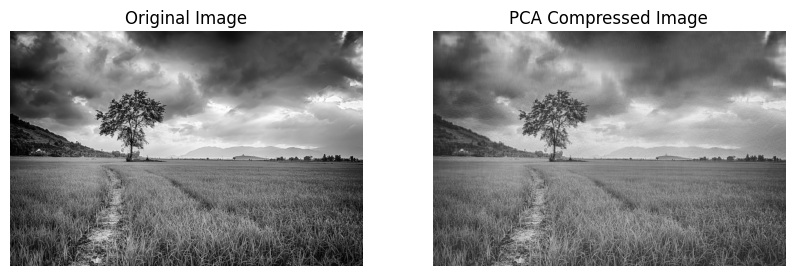

Original Data Size: 2793472
Compressed Data Size: 223696
Number of Principal Components: 164
Explained Variance Ratio: 0.9502218629293895


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.decomposition import PCA

# Step 1: Load the image
image = Image.open("/content/imagepca.jpg").convert("L")


# Step 2: Convert image into a NumPy array
img_array = np.array(image)

print("Original Image Shape:", img_array.shape)

# Step 3: Apply PCA
pca = PCA(n_components=0.95)

# Step 4: Transform the image
compressed_data = pca.fit_transform(img_array)

# Step 5: Reconstruct the image
reconstructed_image = pca.inverse_transform(compressed_data)

print("ReconstructedImage Shape:", reconstructed_image.shape)
# Step 6: Display original and compressed images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_array, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(reconstructed_image, cmap="gray")
plt.title("PCA Compressed Image")
plt.axis("off")

plt.show()

# Step 7: Display compression information
print("Original Data Size:", img_array.size)
print("Compressed Data Size:", compressed_data.size)
print("Number of Principal Components:", pca.n_components_)
print("Explained Variance Ratio:", pca.explained_variance_ratio_.sum())


Original dataset shape: (5000, 784)
Compressed dataset shape: (5000, 148)


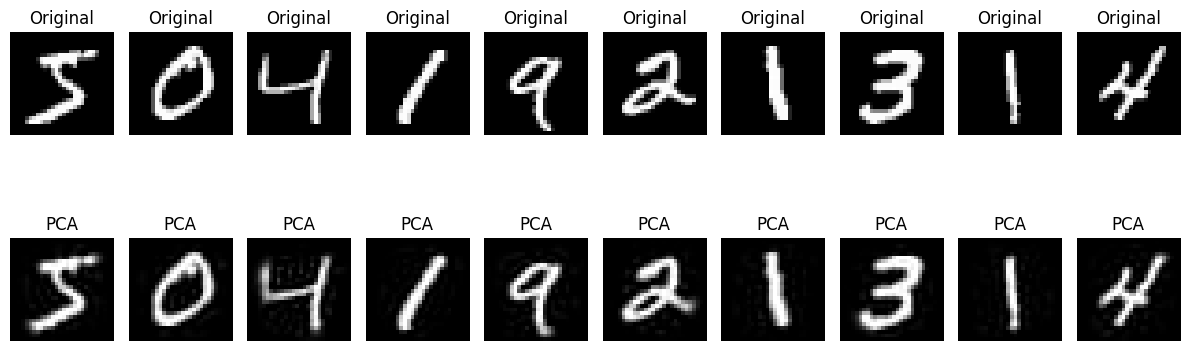

Original features: 784
Reduced features: 148
Explained variance: 0.9501
Dimensionality reduction: 81.12 %


In [ ]:

# 1. Import libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA

# 2. Load MNIST dataset
mnist = fetch_openml(
    "mnist_784",
    version=1,
    as_frame=False
)

X = mnist.data


# 3. Use a subset to make execution faster
#Selects the first 5,000 images to reduce execution time
X = X[:5000]



print("Original dataset shape:", X.shape)

# 4. Normalize pixel values between 0 and 1
X = X / 255.0

# 5. Apply PCA
pca = PCA(n_components=0.95)

# 6. Fit PCA and reduce dimensions
X_compressed = pca.fit_transform(X)

print("Compressed dataset shape:",
      X_compressed.shape)

# 7. Reconstruct the images
X_reconstructed = pca.inverse_transform(X_compressed)

# 8. Display original and reconstructed images
plt.figure(figsize=(12, 5))

for i in range(10):

    # Original image
    plt.subplot(2, 10, i + 1)
    plt.imshow(X[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # Reconstructed image
    plt.subplot(2, 10, i + 11)
    plt.imshow(
        X_reconstructed[i].reshape(28, 28),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    plt.title("PCA")
    plt.axis("off")

plt.tight_layout()
plt.show()

# 9. Display compression information
print("Original features:", X.shape[1])
print("Reduced features:", pca.n_components_)
print("Explained variance:",
      round(pca.explained_variance_ratio_.sum(), 4))

# 10. Calculate dimensionality reduction
reduction = (
    1 - X_compressed.shape[1] / X.shape[1]
) * 100

print("Dimensionality reduction:",
      round(reduction, 2), "%")


"mnist_784"	Selects the handwritten digit dataset
version=1	Specifies the dataset version
as_frame=False	Provides numerical arrays suitable for image processing